In [2]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize


In [3]:
class data():
    def __init__(self,path,period,start_date, end_date,BG,BG_ds,correlation='no',g_err=2,i_err=2):
        self.path = path
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(self.start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(self.end_date)),drop=True)
        self.fluxes=self.fluxes.where((self.fluxes.latitude>=analy_region_lat[0])&(self.fluxes.latitude<=analy_region_lat[1])&(self.fluxes.longitude>=analy_region_lon[0])&(self.fluxes.longitude<=analy_region_lon[1]),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/RemoTeC_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/2x2/{self.correlation}_correlation/footprint_spec001_mr/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        #self.read_gosat()
        #self.read_insitu()
        #self.read_tccon()

In [4]:
class inversion():
    def __init__(self,path,period,start_date, end_date,analysis_start_date, analysis_end_date,color,BG,BG_ds,correlations,g_err=2,i_err=2):
        self.path = path
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.analysis_start_date=analysis_start_date
        self.analysis_end_date=analysis_end_date
        self.correlations=correlations
        self.color=color
        self.BG=BG
        self.BG_ds=BG_ds
        self.data={}
        self.g_err=g_err
        self.i_err=i_err
    def read_data(self):
        for i in range(len(self.correlations)):
            self.data[self.correlations[i]]=data(self.path,self.period,self.analysis_start_date, self.analysis_end_date,self.BG,self.BG_ds,correlation=self.correlations[i],g_err=self.g_err,i_err=self.i_err)
            self.data[self.correlations[i]].read_data()
            self.data[self.correlations[i]].color=self.color[i]
    
                

In [5]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
            ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                               color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [6]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [7]:
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2020,10,1), dt.date(2022,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/covariance_matrix/'

with: complete covariance matrix calculated from flattened array; no cut-off
with_fixed: covariance matrix calculated from dimensional array 
with_fixed_02: cut-off after 2 correlation lengths
with_fixed_03: cut-off after 4 correlation lengths
with_fixed_04: cut-off after 3 correlation lengths
with_fixed_05: 

In [8]:
path='inversions_new/TM5_test_corr_matrix'
correlations=['with_fixed','with_fixed_02','with_fixed_03','with_fixed_04','with_fixed_05']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'
inversion_TM5=inversion(path,period,start_date, end_date,analysis_start_date,analysis_end_date,color,BG,BG_ds,correlations)
inversion_TM5.read_data()


In [9]:
path='inversions_TM5_new_insitu_test_old_with'
correlations=['with']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'
inversion_test=inversion(path,period,start_date, end_date,analysis_start_date,analysis_end_date,color,BG,BG_ds,correlations)
inversion_test.read_data()



In [10]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [11]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

/tmp/ipykernel_663775/1737806252.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_663775/1737806252.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_663775/1737806252.py:71: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


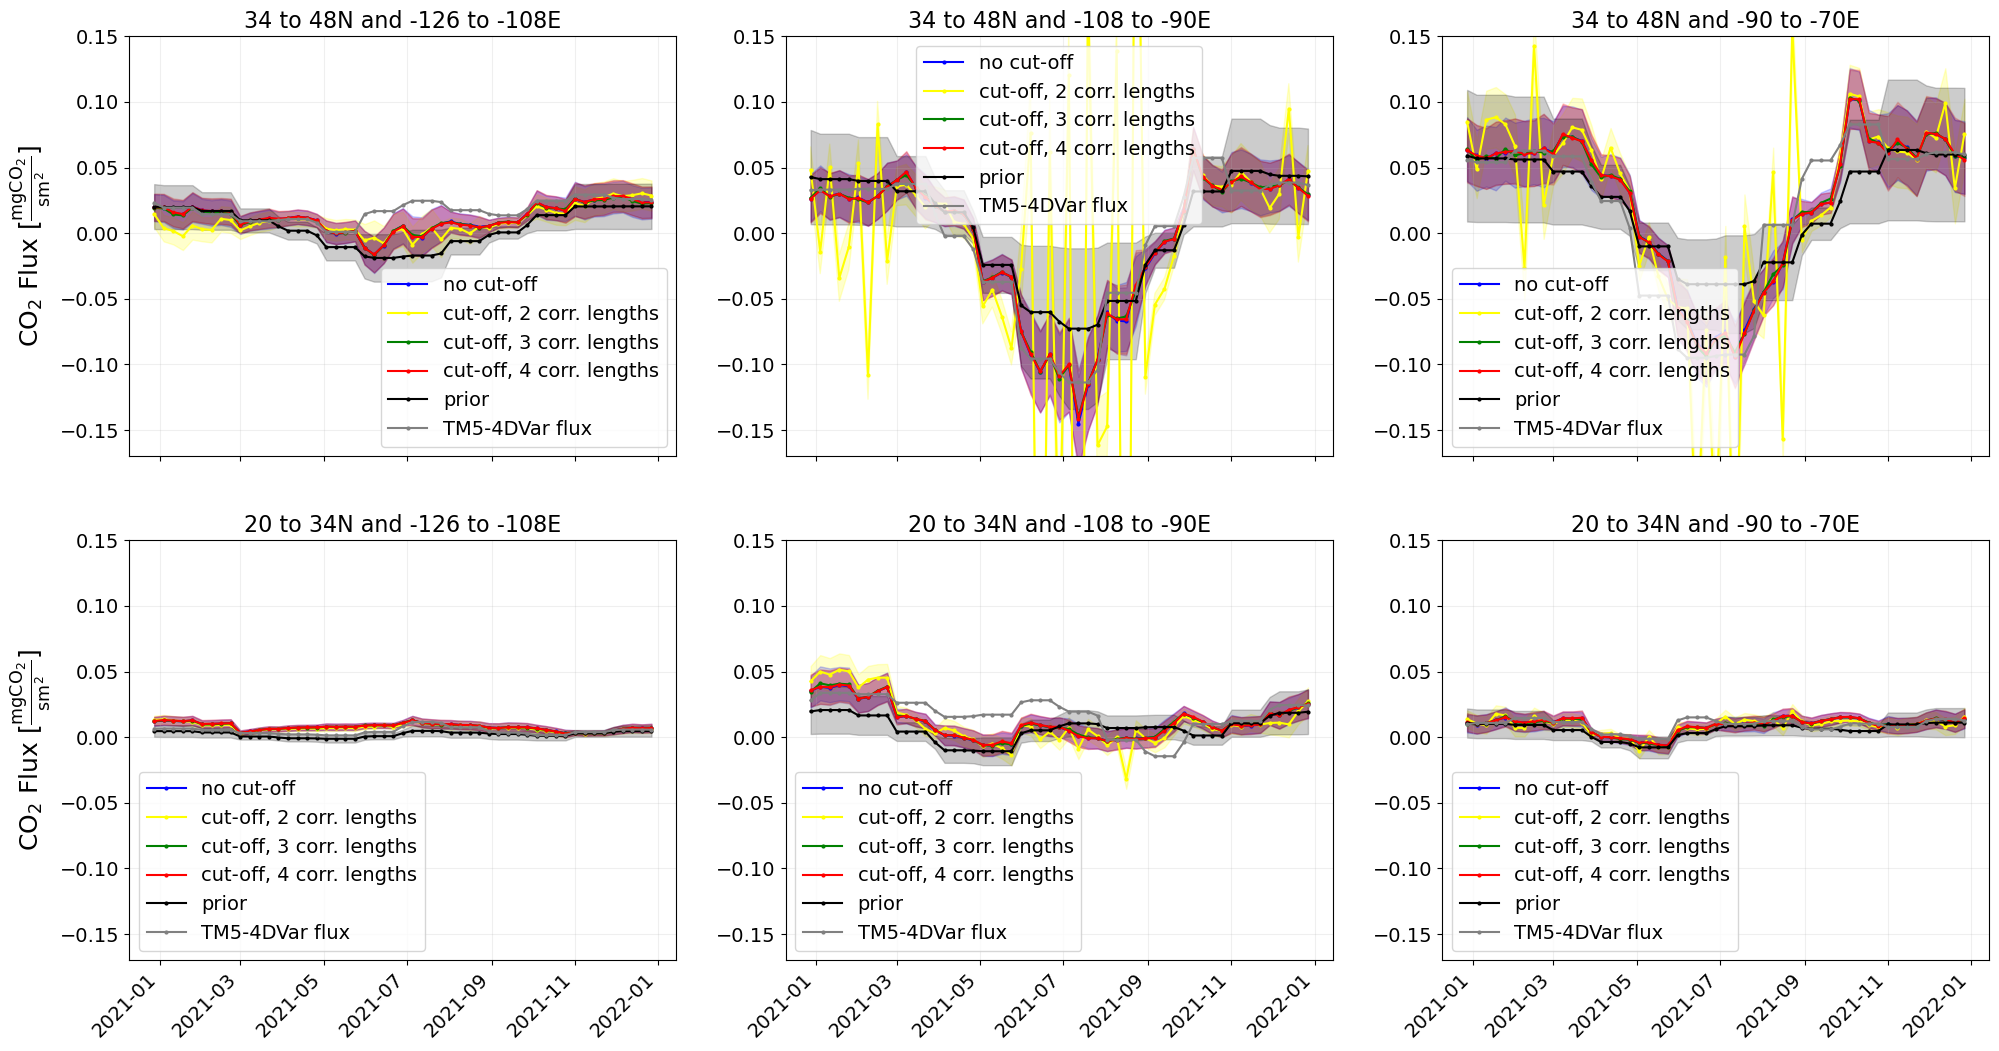

In [12]:
inv_temp=inversion_TM5
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        
        inv_temp=inversion_test
        corr='with'
        temp=inv_temp.data[corr].fluxes.where(((inv_temp.data[corr].fluxes.latitude>= regions_lat[-i-2]) &(inv_temp.data[corr].fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c='blue', marker='o', markersize=2, label=f'no cut-off')
        axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color='purple', alpha=0.2) 

        inv_temp=inversion_TM5
        corr='with_fixed_02'
        temp=inv_temp.data[corr].fluxes.where(((inv_temp.data[corr].fluxes.latitude>= regions_lat[-i-2]) &(inv_temp.data[corr].fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c='yellow', marker='o', markersize=2, label=f'cut-off, 2 corr. lengths')
        axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color='yellow', alpha=0.2) 

        inv_temp=inversion_TM5
        corr='with_fixed_04'
        temp=inv_temp.data[corr].fluxes.where(((inv_temp.data[corr].fluxes.latitude>= regions_lat[-i-2]) &(inv_temp.data[corr].fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c='green', marker='o', markersize=2, label=f'cut-off, 3 corr. lengths')
        axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color='blue', alpha=0.2) 


        inv_temp=inversion_TM5
        corr='with_fixed_03'
        temp=inv_temp.data[corr].fluxes.where(((inv_temp.data[corr].fluxes.latitude>= regions_lat[-i-2]) &(inv_temp.data[corr].fluxes.latitude<regions_lat[-i-1])),drop=True)
        temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
        temp=temp.mean(['latitude','longitude'])
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c='r', marker='o', markersize=2, label=f'cut-off, 4 corr. lengths')
        axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color='r', alpha=0.2) 

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
        #axs[i,j].tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_cutoff.pdf',bbox_inches='tight',dpi=500)#,transparent=True)
plt.show()
#plt.close()

with: complete covariance matrix calculated from flattened array; no cut-off \
with_fixed: covariance matrix calculated from dimensional array \
with_fixed_02: cut-off after 2 correlation lengths \
with_fixed_03: cut-off after 4 correlation lengths \
with_fixed_04: cut-off after 3 correlation lengths \
with_fixed_05: 

In [13]:
diff=np.abs(inversion_TM5.data['with_fixed_02'].fluxes.TM5_posterior_flux-inversion_test.data['with'].fluxes.TM5_posterior_flux)
print('difference cuttoff after 2 lengths')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=(np.abs(inversion_TM5.data['with_fixed_02'].fluxes.TM5_posterior_flux-inversion_test.data['with'].fluxes.TM5_posterior_flux))/inversion_test.data['with'].fluxes.TM5_posterior_std
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference cuttoff after 2 lengths
sum: 0.0006476210792318114
max: 3.870903025690534e-06
min: 9.452428476767657e-15
mean: 3.117159603541641e-08
per standard deviation
max: 59.52822239661209
min: 2.7655302150755952e-05
mean: 1.4410342699302503


In [14]:
diff=np.abs(inversion_TM5.data['with_fixed_04'].fluxes.TM5_posterior_flux-inversion_test.data['with'].fluxes.TM5_posterior_flux)
print('difference cuttoff after 3 lengths')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=(np.abs(inversion_TM5.data['with_fixed_04'].fluxes.TM5_posterior_flux-inversion_test.data['with'].fluxes.TM5_posterior_flux))/inversion_test.data['with'].fluxes.TM5_posterior_std
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference cuttoff after 3 lengths
sum: 4.4375738719334856e-05
max: 5.0723381433962616e-08
min: 1.3954752764869243e-15
mean: 2.1359134924593212e-09
per standard deviation
max: 1.8264603235815644
min: 2.581298242909728e-05
mean: 0.17900637086159135


In [ ]:
diff=np.abs(inversion_TM5.data['with_fixed_03'].fluxes.TM5_posterior_flux-inversion_test.data['with'].fluxes.TM5_posterior_flux)
print('difference cuttoff after 4 lengths')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=(np.abs(inversion_TM5.data['with_fixed_03'].fluxes.TM5_posterior_flux-inversion_test.data['with'].fluxes.TM5_posterior_flux))/inversion_test.data['with'].fluxes.TM5_posterior_std
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference cuttoff after 3 lengths
sum: 2.028124757641047e-05
max: 3.598010352253429e-08
min: 1.5238799601361102e-14
mean: 9.761863484987712e-10
per standard deviation
max: 0.7376594881203034
min: 5.628659587043819e-06
mean: 0.08443851010956838
